File ground_truth.xml telah berhasil dibuat. Total: 33 bounding box terdeteksi.


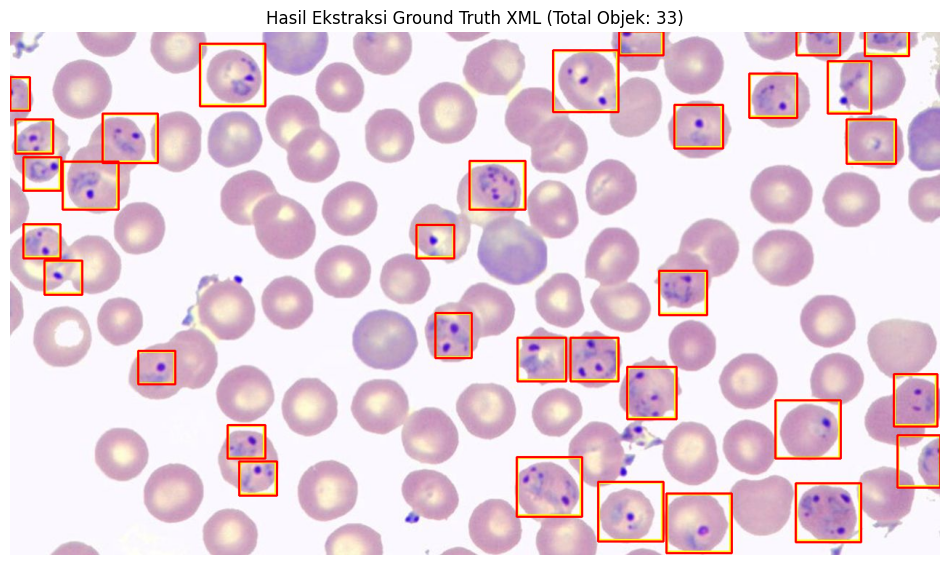

In [14]:
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

def create_ground_truth_xml(gt_img_file="ground-truth.jpeg", xml_out_file="ground_truth.xml"):
    img_gt = cv2.imread(gt_img_file)
        
    img_height, img_width, _ = img_gt.shape
    
    hsv_gt = cv2.cvtColor(img_gt, cv2.COLOR_BGR2HSV)
    
    yellow_lower = np.array([15, 80, 80], dtype=np.uint8)
    yellow_upper = np.array([40, 255, 255], dtype=np.uint8)
    yellow_mask = cv2.inRange(hsv_gt, yellow_lower, yellow_upper)
    
    inv_mask = cv2.bitwise_not(yellow_mask)
    corner_points = [(0, 0), (img_width - 1, 0), (0, img_height - 1), (img_width - 1, img_height - 1)]
    for seed in corner_points:
        cv2.floodFill(inv_mask, None, seed, 0)
        
    contours, _ = cv2.findContours(inv_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    xml_root = ET.Element("annotation")
    ET.SubElement(xml_root, "folder").text = "data_input"
    ET.SubElement(xml_root, "filename").text = "raw.jpeg"
    ET.SubElement(xml_root, "path").text = "raw.jpeg"
    
    source_node = ET.SubElement(xml_root, "source")
    ET.SubElement(source_node, "database").text = "Unknown"
    
    size_node = ET.SubElement(xml_root, "size")
    ET.SubElement(size_node, "width").text = str(img_width)
    ET.SubElement(size_node, "height").text = str(img_height)
    ET.SubElement(size_node, "depth").text = "3"
    
    ET.SubElement(xml_root, "segmented").text = "0"
    
    annotated_img = img_gt.copy()
    box_count = 0
    
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w <= 12 or h <= 12:
            continue
            
        xmin = max(0, x - 3)
        ymin = max(0, y - 3)
        xmax = min(img_width, x + w + 3)
        ymax = min(img_height, y + h + 3)
        
        obj_node = ET.SubElement(xml_root, "object")
        ET.SubElement(obj_node, "name").text = "cell"
        ET.SubElement(obj_node, "pose").text = "Unspecified"
        ET.SubElement(obj_node, "truncated").text = "0"
        ET.SubElement(obj_node, "difficult").text = "0"
        
        box_node = ET.SubElement(obj_node, "bndbox")
        ET.SubElement(box_node, "xmin").text = str(xmin)
        ET.SubElement(box_node, "ymin").text = str(ymin)
        ET.SubElement(box_node, "xmax").text = str(xmax)
        ET.SubElement(box_node, "ymax").text = str(ymax)
        
        cv2.rectangle(annotated_img, (xmin, ymin), (xmax, ymax), (0, 0, 255), 2)
        box_count += 1
        
    ET.ElementTree(xml_root).write(xml_out_file)
    print(f"File {xml_out_file} telah berhasil dibuat. Total: {box_count} bounding box terdeteksi.")
    
    return annotated_img, box_count

gt_result_img, total_gt_boxes = create_ground_truth_xml()

# visualisasi
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(gt_result_img, cv2.COLOR_BGR2RGB))
plt.title(f"Hasil Ekstraksi Ground Truth XML (Total Objek: {total_gt_boxes})", fontsize=12)
plt.axis("off")
plt.show()


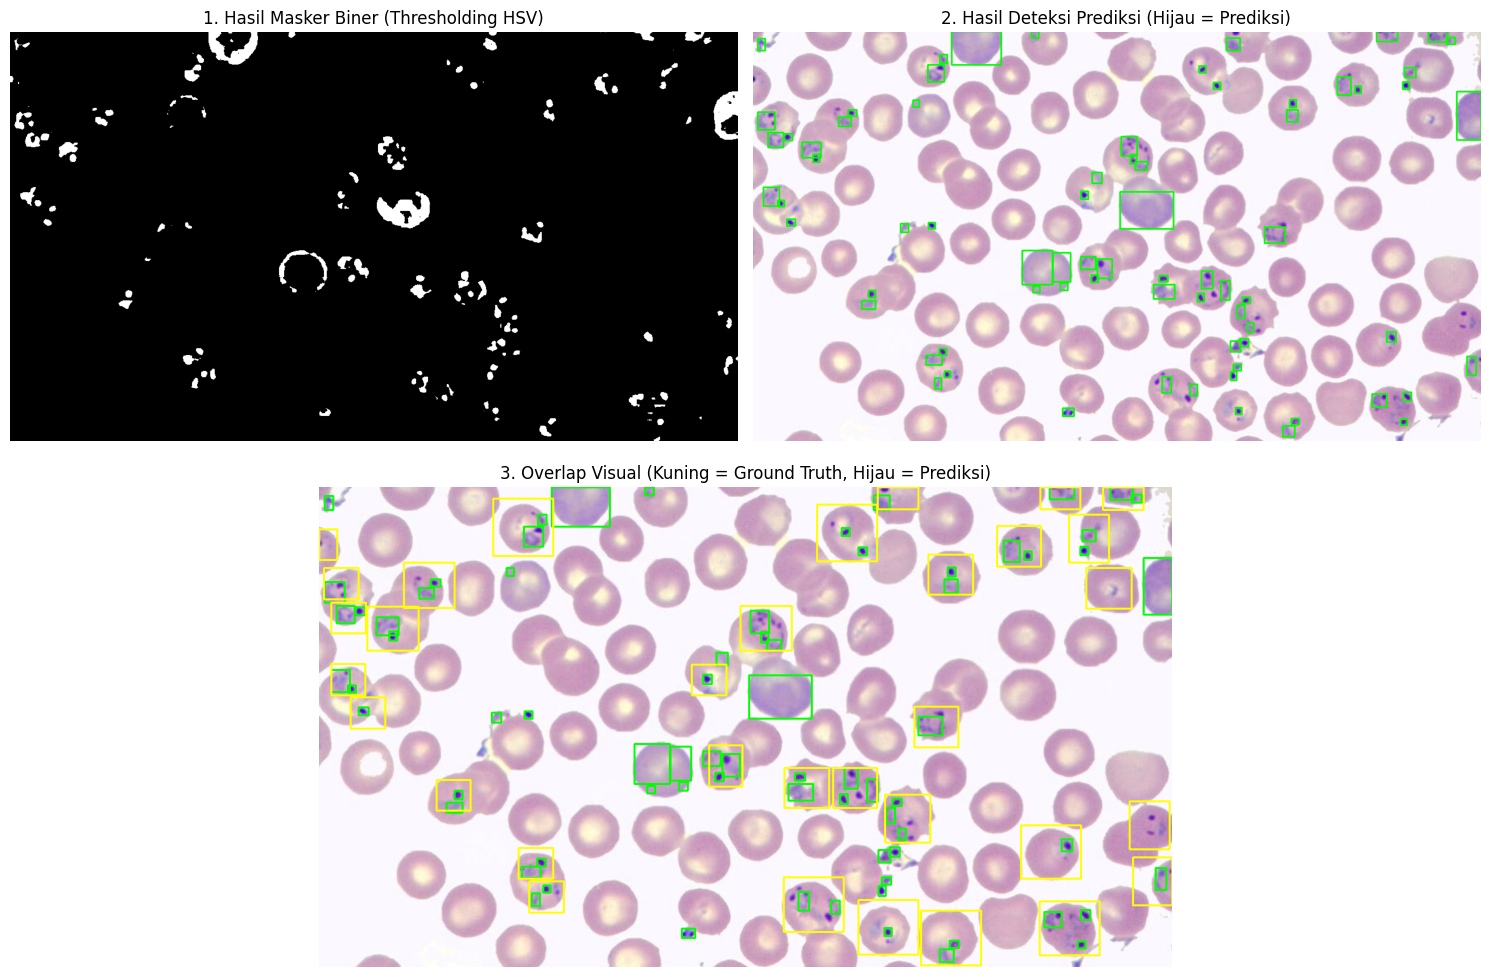

 True Positive (TP)  : 30
 False Positive (FP) : 44
 False Negative (FN) : 3
 Precision           : 0.405
 Recall              : 0.909 
 F1-Score            : 0.561


In [15]:
def load_voc_bounding_boxes(xml_filepath):
    tree = ET.parse(xml_filepath)
    root = tree.getroot()
    bbox_list = []
    for obj in root.findall("object"):
        box = obj.find("bndbox")
        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)
        bbox_list.append((xmin, ymin, xmax, ymax))
    return bbox_list

def calculate_box_iou(box_a, box_b):
    x_min = max(box_a[0], box_b[0])
    y_min = max(box_a[1], box_b[1])
    x_max = min(box_a[2], box_b[2])
    y_max = min(box_a[3], box_b[3])
    
    inter_area = max(0, x_max - x_min) * max(0, y_max - y_min)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    
    union_area = area_a + area_b - inter_area
    return inter_area / float(union_area + 1e-6)

def is_center_inside_box(pred_box, gt_box):
    center_x = (pred_box[0] + pred_box[2]) // 2
    center_y = (pred_box[1] + pred_box[3]) // 2
    return (gt_box[0] <= center_x <= gt_box[2]) and (gt_box[1] <= center_y <= gt_box[3])

# baca raw img dan file xml
raw_img_path = "raw.jpeg"
xml_gt_path = "ground_truth.xml"

img_raw = cv2.imread(raw_img_path)

img_prediction = img_raw.copy()
img_overlay = img_raw.copy()

hsv_raw = cv2.cvtColor(img_raw, cv2.COLOR_BGR2HSV)
purple_lower = np.array([125, 50, 50], dtype=np.uint8)
purple_upper = np.array([140, 255, 255], dtype=np.uint8)
parasite_mask = cv2.inRange(hsv_raw, purple_lower, purple_upper)

contours_pred, _ = cv2.findContours(parasite_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
predicted_boxes = []

for cnt in contours_pred:
    x, y, w, h = cv2.boundingRect(cnt)
    if w <= 10 or h <= 10:
        continue
    p_box = (x, y, x + w, y + h)
    predicted_boxes.append(p_box)
    
    cv2.rectangle(img_prediction, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.rectangle(img_overlay, (x, y), (x + w, y + h), (0, 255, 0), 2)

ground_truth_boxes = load_voc_bounding_boxes(xml_gt_path)
for box in ground_truth_boxes:
    cv2.rectangle(img_overlay, (box[0], box[1]), (box[2], box[3]), (0, 255, 255), 2)

iou_threshold = 0.20
matched_gt_indices = set()
tp_count = 0
fp_count = 0

for p_box in predicted_boxes:
    match_found = False
    for idx, g_box in enumerate(ground_truth_boxes):
        if idx in matched_gt_indices:
            continue
        if calculate_box_iou(p_box, g_box) > iou_threshold or is_center_inside_box(p_box, g_box):
            match_found = True
            matched_gt_indices.add(idx)
            break
            
    if match_found:
        tp_count += 1
    else:
        fp_count += 1

fn_count = len(ground_truth_boxes) - tp_count
precision_val = tp_count / float(tp_count + fp_count + 1e-6)
recall_val = tp_count / float(tp_count + fn_count + 1e-6)
f1_val = 2.0 * (precision_val * recall_val) / (precision_val + recall_val + 1e-6)

fig = plt.figure(figsize=(15, 10))

ax1 = plt.subplot2grid((2, 2), (0, 0))
ax1.imshow(parasite_mask, cmap="gray")
ax1.set_title("1. Hasil Masker Biner (Thresholding HSV)")
ax1.axis("off")

ax2 = plt.subplot2grid((2, 2), (0, 1))
ax2.imshow(cv2.cvtColor(img_prediction, cv2.COLOR_BGR2RGB))
ax2.set_title("2. Hasil Deteksi Prediksi (Hijau = Prediksi)")
ax2.axis("off")

ax3 = plt.subplot2grid((2, 2), (1, 0), colspan=2)
ax3.imshow(cv2.cvtColor(img_overlay, cv2.COLOR_BGR2RGB))
ax3.set_title("3. Overlap Visual (Kuning = Ground Truth, Hijau = Prediksi)")
ax3.axis("off")

plt.tight_layout()
plt.show()

print(f" True Positive (TP)  : {tp_count}")
print(f" False Positive (FP) : {fp_count}")
print(f" False Negative (FN) : {fn_count}")
print(f" Precision           : {precision_val:.3f}")
print(f" Recall              : {recall_val:.3f} ")
print(f" F1-Score            : {f1_val:.3f}")
